In [2]:
import tensorflow as tf
import tensorflow_datasets as tfds
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
!pip install -q importlib_resources

In [4]:
(ds_train, ds_val, ds_test), info = tfds.load(
    "oxford_flowers102",
    split=["train", "validation", "test"],
    as_supervised=True,
    with_info=True
)

NUM_CLASSES = info.features["label"].num_classes

print("Number of classes:", NUM_CLASSES)
print("Training images:", info.splits["train"].num_examples)
print("Validation images:", info.splits["validation"].num_examples)
print("Test images:", info.splits["test"].num_examples)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/3 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

...

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_flowers102/incomplete.3YBWC9_2.1.1/oxford_flowers102-test.tfrecord-…

Generating validation examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_flowers102/incomplete.3YBWC9_2.1.1/oxford_flowers102-validation.tfr…

Dataset oxford_flowers102 downloaded and prepared to /root/tensorflow_datasets/oxford_flowers102/2.1.1. Subsequent calls will reuse this data.
Number of classes: 102
Training images: 1020
Validation images: 1020
Test images: 6149


Number of classes: 102
Training dataset: 1020
Validation dataset: 1020
Test dataset: 6149


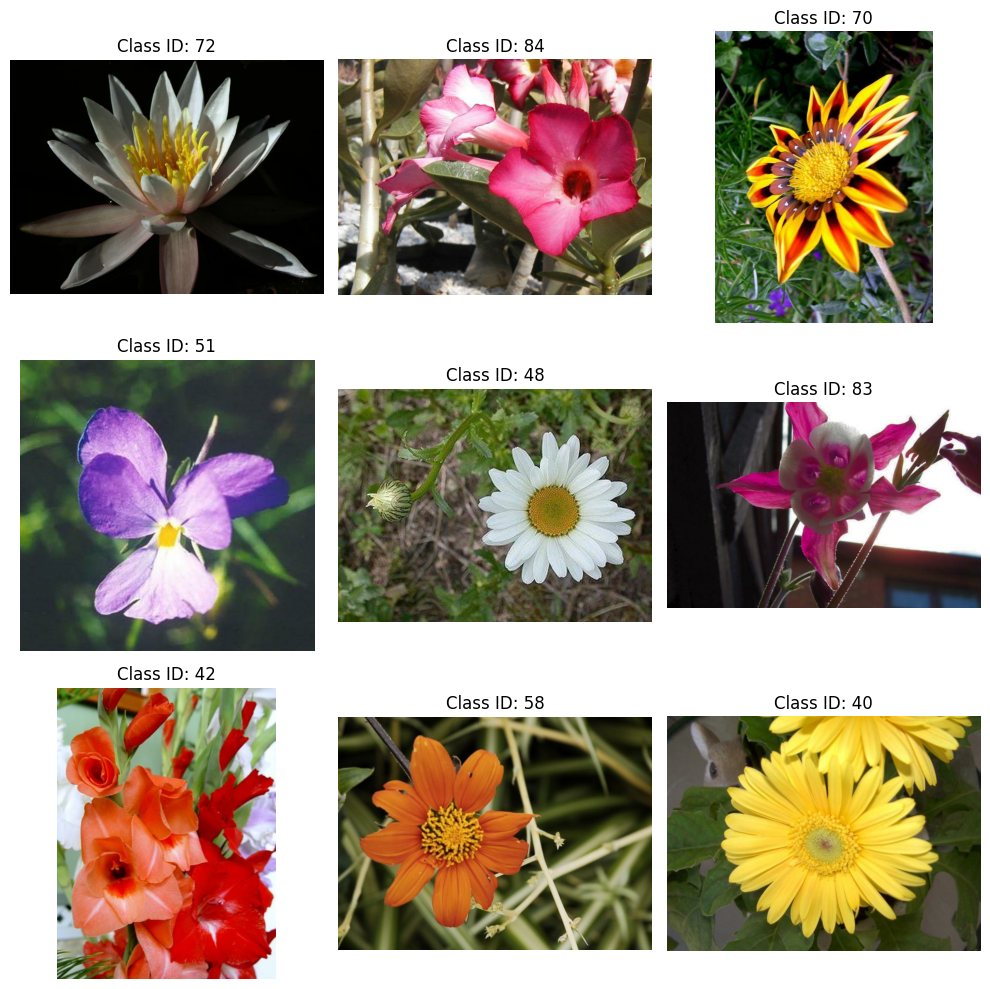

In [5]:


print("Number of classes:", NUM_CLASSES)

print("Training dataset:", info.splits["train"].num_examples)
print("Validation dataset:", info.splits["validation"].num_examples)
print("Test dataset:", info.splits["test"].num_examples)

plt.figure(figsize=(10, 10))

for i, (image, label) in enumerate(ds_train.take(9)):
    plt.subplot(3, 3, i + 1)
    plt.imshow(image)
    plt.title(f"Class ID: {label.numpy()}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [6]:


IMG_SIZE = 224
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def preprocess(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = tf.cast(image, tf.float32)
    return image, label

train_ds = (
    ds_train
    .map(preprocess, num_parallel_calls=AUTOTUNE)
    .shuffle(1020, seed=42)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

val_ds = (
    ds_val
    .map(preprocess, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

test_ds = (
    ds_test
    .map(preprocess, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

print("Preprocessing completed!")

Preprocessing completed!


In [7]:


data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.10),
    tf.keras.layers.RandomZoom(0.10)
])


base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False


inputs = tf.keras.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)

outputs = tf.keras.layers.Dense(
    102,
    activation="softmax"
)(x)

model = tf.keras.Model(inputs, outputs)

print("CNN model created successfully!")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
CNN model created successfully!


In [8]:


model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 102)            │       130,662 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,388,646 (9.11 MB)

 Trainable params: 130,662 (510.40 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [9]:


callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "best_flower_model.keras",
        monitor="val_accuracy",
        save_best_only=True
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=callbacks
)

Epoch 1/8
32/32 ━━━━━━━━━━━━━━━━━━━━ 17s 214ms/step - accuracy: 0.0657 - loss: 4.6575 - val_accuracy: 0.2471 - val_loss: 3.4302
Epoch 2/8
32/32 ━━━━━━━━━━━━━━━━━━━━ 6s 139ms/step - accuracy: 0.3490 - loss: 2.8229 - val_accuracy: 0.5588 - val_loss: 2.3831
Epoch 3/8
32/32 ━━━━━━━━━━━━━━━━━━━━ 6s 137ms/step - accuracy: 0.6137 - loss: 1.8777 - val_accuracy: 0.6451 - val_loss: 1.8583
Epoch 4/8
32/32 ━━━━━━━━━━━━━━━━━━━━ 6s 137ms/step - accuracy: 0.7539 - loss: 1.3441 - val_accuracy: 0.6941 - val_loss: 1.5602
Epoch 5/8
32/32 ━━━━━━━━━━━━━━━━━━━━ 10s 137ms/step - accuracy: 0.8304 - loss: 1.0196 - val_accuracy: 0.7176 - val_loss: 1.3797
Epoch 6/8
32/32 ━━━━━━━━━━━━━━━━━━━━ 7s 163ms/step - accuracy: 0.8598 - loss: 0.8206 - val_accuracy: 0.7549 - val_loss: 1.2444
Epoch 7/8
32/32 ━━━━━━━━━━━━━━━━━━━━ 6s 127ms/step - accuracy: 0.8843 - loss: 0.6696 - val_accuracy: 0.7490 - val_loss: 1.1693
Epoch 8/8
32/32 ━━━━━━━━━━━━━━━━━━━━ 11s 148ms/step - accuracy: 0.9078 - loss: 0.5801 - val_accuracy: 0.7598 

In [10]:


test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

193/193 ━━━━━━━━━━━━━━━━━━━━ 12s 61ms/step - accuracy: 0.7266 - loss: 1.2276
Test Loss: 1.2276
Test Accuracy: 72.66 %


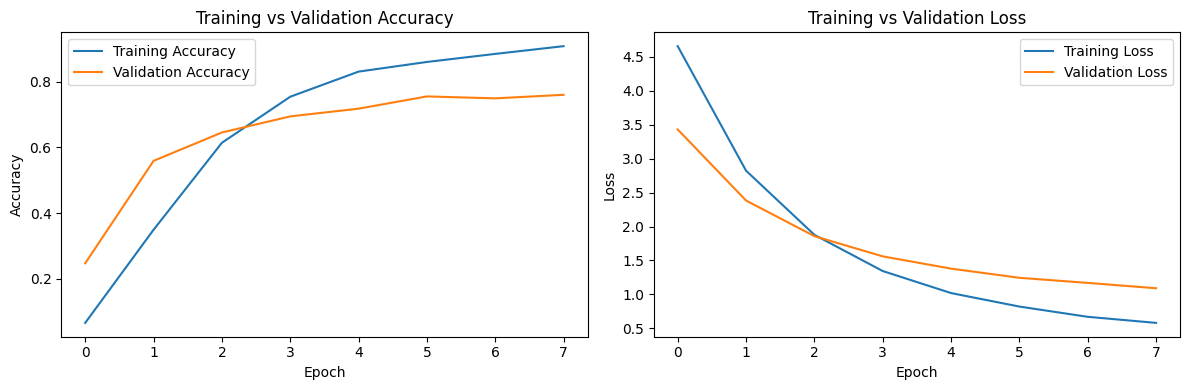

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))


plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()


plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [12]:
import numpy as np
from sklearn.metrics import classification_report

y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

probabilities = model.predict(test_ds, verbose=1)
y_pred = np.argmax(probabilities, axis=1)

class_names = info.features["label"].names

print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(102),
    target_names=class_names,
    zero_division=0
))

193/193 ━━━━━━━━━━━━━━━━━━━━ 15s 73ms/step
                           precision    recall  f1-score   support

            pink primrose       0.41      0.35      0.38        20
hard-leaved pocket orchid       0.90      0.93      0.91        40
         canterbury bells       0.25      0.20      0.22        20
                sweet pea       0.38      0.42      0.40        36
         english marigold       0.44      0.82      0.57        45
               tiger lily       1.00      0.96      0.98        25
              moon orchid       0.73      0.80      0.76        20
         bird of paradise       0.97      1.00      0.98        65
                monkshood       0.44      0.92      0.60        26
            globe thistle       0.71      0.96      0.81        25
               snapdragon       0.65      0.30      0.41        67
              colt's foot       0.98      0.64      0.77        67
              king protea       0.96      0.76      0.85        29
            spear 

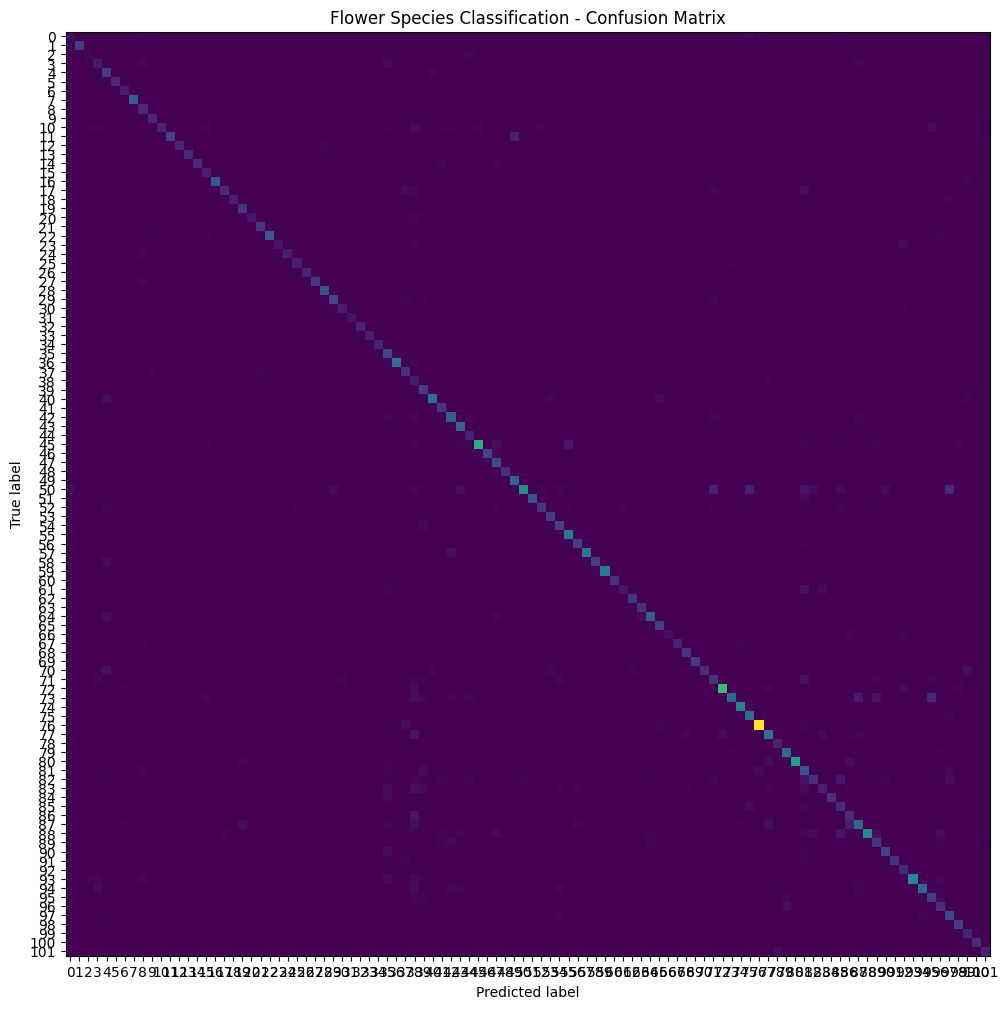

In [13]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(102)
)

fig, ax = plt.subplots(figsize=(12, 12))

ConfusionMatrixDisplay(
    confusion_matrix=cm
).plot(
    ax=ax,
    include_values=False,
    colorbar=False
)

plt.title("Flower Species Classification - Confusion Matrix")
plt.show()

In [14]:
model.save("flower_species_classifier.keras")

print("Model saved successfully!")

Model saved successfully!


In [15]:
from google.colab import files
files.download("flower_species_classifier.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>